In [3]:
print("HCP Targeting & Prediction Project")

HCP Targeting & Prediction Project


# **Data Collection & Exploration**

In [4]:
import requests
import pandas as pd
import time

url = "https://data.cms.gov/data-api/v1/dataset/f68114ed-f854-4ffc-9c6e-ed78b5e2f8d0/data"

all_rows = []
offset = 0
batch_size = 5000

while True:
    response = requests.get(
        url,
        params={
            "filter[Brnd_Name]": "Jardiance",
            "size": batch_size,
            "offset": offset
        },
        timeout=60
    )

    response.raise_for_status()
    rows = response.json()

    if not rows:
        break

    all_rows.extend(rows)
    offset += len(rows)

    print("Rows retrieved so far:", len(all_rows))

    if len(rows) < batch_size:
        break

    time.sleep(0.2)

df_jardiance = pd.DataFrame(all_rows)

df_jardiance.to_csv("jardiance_2021.csv", index=False)

print("\nTotal rows:", len(df_jardiance))
print("Columns:", df_jardiance.columns.tolist())

display(df_jardiance.head())

Rows retrieved so far: 5000
Rows retrieved so far: 10000
Rows retrieved so far: 15000
Rows retrieved so far: 20000
Rows retrieved so far: 25000
Rows retrieved so far: 30000
Rows retrieved so far: 35000
Rows retrieved so far: 40000
Rows retrieved so far: 45000
Rows retrieved so far: 50000
Rows retrieved so far: 55000
Rows retrieved so far: 60000
Rows retrieved so far: 65000
Rows retrieved so far: 70000
Rows retrieved so far: 75000
Rows retrieved so far: 80000
Rows retrieved so far: 85000
Rows retrieved so far: 87157

Total rows: 87157
Columns: ['Prscrbr_NPI', 'Prscrbr_Last_Org_Name', 'Prscrbr_First_Name', 'Prscrbr_City', 'Prscrbr_State_Abrvtn', 'Prscrbr_State_FIPS', 'Prscrbr_Type', 'Prscrbr_Type_Src', 'Brnd_Name', 'Gnrc_Name', 'Tot_Clms', 'Tot_30day_Fills', 'Tot_Day_Suply', 'Tot_Drug_Cst', 'Tot_Benes', 'GE65_Sprsn_Flag', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills', 'GE65_Tot_Drug_Cst', 'GE65_Tot_Day_Suply', 'GE65_Bene_Sprsn_Flag', 'GE65_Tot_Benes']


,Prscrbr_NPI,Prscrbr_Last_Org_Name,Prscrbr_First_Name,Prscrbr_City,Prscrbr_State_Abrvtn,Prscrbr_State_FIPS,Prscrbr_Type,Prscrbr_Type_Src,Brnd_Name,Gnrc_Name,...,Tot_Day_Suply,Tot_Drug_Cst,Tot_Benes,GE65_Sprsn_Flag,GE65_Tot_Clms,GE65_Tot_30day_Fills,GE65_Tot_Drug_Cst,GE65_Tot_Day_Suply,GE65_Bene_Sprsn_Flag,GE65_Tot_Benes
0,1003000530,Semonche,Amanda,Quakertown,PA,42,Internal Medicine,Claim-Specialty,Jardiance,Empagliflozin,...,1335,25774.01,,#,,,,,*,
1,1003000902,Lohano,Jaivanti,Louisville,KY,21,Family Practice,Claim-Specialty,Jardiance,Empagliflozin,...,1710,32727.42,,,16,26,14831.1,780,*,
2,1003002049,Srinivasan,Lakshmi,Fremont,CA,06,Endocrinology,Claim-Specialty,Jardiance,Empagliflozin,...,2040,38353.97,12,#,,,,,#,
3,1003004201,Philbrick,Natalie,Corpus Christi,TX,48,Internal Medicine,Claim-Specialty,Jardiance,Empagliflozin,...,570,10639.81,,*,,,,,*,
4,1003004839,Darnell,Beverly,Kensington,MD,24,Internal Medicine,Claim-Specialty,Jardiance,Empagliflozin,...,1020,6751.61,11,*,,,,,*,


In [5]:
from google.colab import files
files.download("jardiance_2021.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
print("Total rows:", len(df_jardiance))
print("Unique doctors:", df_jardiance["Prscrbr_NPI"].nunique())
print("Duplicate rows:", df_jardiance.duplicated().sum())
print("Missing values:")
print(df_jardiance[["Prscrbr_NPI", "Brnd_Name", "Tot_Clms"]].isna().sum())

Total rows: 87157
Unique doctors: 87157
Duplicate rows: 0
Missing values:
Prscrbr_NPI    0
Brnd_Name      0
Tot_Clms       0
dtype: int64


In [7]:
print("Data types:")
print(df_jardiance[["Prscrbr_NPI", "Brnd_Name", "Tot_Clms"]].dtypes)
print("\nFirst 5 claim values:")
print(df_jardiance["Tot_Clms"].head())

Data types:
Prscrbr_NPI    object
Brnd_Name      object
Tot_Clms       object
dtype: object

First 5 claim values:
0    19
1    33
2    26
3    13
4    14
Name: Tot_Clms, dtype: object


In [8]:
df_jardiance["Tot_Clms"] = pd.to_numeric(df_jardiance["Tot_Clms"], errors = "coerce")
print("Updated data type:")
print(df_jardiance["Tot_Clms"].dtype)
print("\nFirst 5 claim values:")
print(df_jardiance["Tot_Clms"].head())

Updated data type:
int64

First 5 claim values:
0    19
1    33
2    26
3    13
4    14
Name: Tot_Clms, dtype: int64


In [9]:
print("Missing values after conversion:", df_jardiance["Tot_Clms"].isna().sum())
print("Claims summary:")
print(df_jardiance["Tot_Clms"].describe())

Missing values after conversion: 0
Claims summary:
count    87157.000000
mean        38.048395
std         44.972911
min         11.000000
25%         15.000000
50%         24.000000
75%         43.000000
max       1734.000000
Name: Tot_Clms, dtype: float64


In [10]:
print("Minimum claims:", df_jardiance["Tot_Clms"].min())
print("Maximum claims:", df_jardiance["Tot_Clms"].max())
print("\nTopn 10 records by claims:")
display(
    df_jardiance[["Prscrbr_NPI", "Brnd_Name", "Tot_Clms"]].sort_values(
        by = "Tot_Clms", ascending = False
    ).head(10)
)

Minimum claims: 11
Maximum claims: 1734

Topn 10 records by claims:


,Prscrbr_NPI,Brnd_Name,Tot_Clms
62170,1710074026,Jardiance,1734
53384,1619082625,Jardiance,1711
25152,1285661819,Jardiance,1221
51035,1588633135,Jardiance,1128
27870,1316906738,Jardiance,1101
50339,1578621702,Jardiance,1017
29018,1336103233,Jardiance,948
47371,1548204506,Jardiance,942
78017,1891746129,Jardiance,866
58880,1679560833,Jardiance,855


In [11]:
print("Dataset columns:")
print(df_jardiance.columns.tolist())

Dataset columns:
['Prscrbr_NPI', 'Prscrbr_Last_Org_Name', 'Prscrbr_First_Name', 'Prscrbr_City', 'Prscrbr_State_Abrvtn', 'Prscrbr_State_FIPS', 'Prscrbr_Type', 'Prscrbr_Type_Src', 'Brnd_Name', 'Gnrc_Name', 'Tot_Clms', 'Tot_30day_Fills', 'Tot_Day_Suply', 'Tot_Drug_Cst', 'Tot_Benes', 'GE65_Sprsn_Flag', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills', 'GE65_Tot_Drug_Cst', 'GE65_Tot_Day_Suply', 'GE65_Bene_Sprsn_Flag', 'GE65_Tot_Benes']


In [12]:
import requests
import pandas as pd
url = "https://data.cms.gov/data-api/v1/dataset/f68114ed-f854-4ffc-9c6e-ed78b5e2f8d0/data"
competitor_drugs = ["Farxiga", "Invokana", "Steglatro"]
all_competitor_data = []
for drug in competitor_drugs:
  print(f"Fetching {drug} data...")
  offset = 0
  limit = 5000
  drug_data = []
  while True:
    params = {"size": limit, "offset": offset, "filter[Brnd_Name]": drug}
    response = requests.get(url, params)
    response.raise_for_status()
    batch = response.json()
    if not batch:
      break
    drug_data.extend(batch)
    offset += limit
    if len(batch) < limit:
      break
  drug_df = pd.DataFrame(drug_data)
  print(f"{drug}: {len(drug_df)} records fetched")
  all_competitor_data.append(drug_df)
competitor_df = pd.concat(all_competitor_data, ignore_index = True)
print("\nTotal competitor records:", len(competitor_df))
competitor_df.head()

Fetching Farxiga data...
Farxiga: 38921 records fetched
Fetching Invokana data...
Invokana: 12880 records fetched
Fetching Steglatro data...
Steglatro: 634 records fetched

Total competitor records: 52435


,Prscrbr_NPI,Prscrbr_Last_Org_Name,Prscrbr_First_Name,Prscrbr_City,Prscrbr_State_Abrvtn,Prscrbr_State_FIPS,Prscrbr_Type,Prscrbr_Type_Src,Brnd_Name,Gnrc_Name,...,Tot_Day_Suply,Tot_Drug_Cst,Tot_Benes,GE65_Sprsn_Flag,GE65_Tot_Clms,GE65_Tot_30day_Fills,GE65_Tot_Drug_Cst,GE65_Tot_Day_Suply,GE65_Bene_Sprsn_Flag,GE65_Tot_Benes
0,1003004201,Philbrick,Natalie,Corpus Christi,TX,48,Internal Medicine,Claim-Specialty,Farxiga,Dapagliflozin Propanediol,...,950,17111.12,,#,,,,,*,
1,1003006552,Quinonez,Alner,Fort Meade,FL,12,Family Practice,Claim-Specialty,Farxiga,Dapagliflozin Propanediol,...,1110,18874.68,,*,,,,,*,
2,1003007048,Fereidouni,Sam,Scottsdale,AZ,04,Family Practice,Claim-Specialty,Farxiga,Dapagliflozin Propanediol,...,810,14130.64,,,17,27,14130.64,810,*,
3,1003007980,Bernal,Juan,Birmingham,AL,01,Interventional Cardiology,Claim-Specialty,Farxiga,Dapagliflozin Propanediol,...,1080,18102.37,,#,,,,,*,
4,1003008095,House,Robin,London,KY,21,Nurse Practitioner,Claim-Specialty,Farxiga,Dapagliflozin Propanediol,...,1020,18330.56,,#,,,,,*,


In [13]:
print("Records by drugs:")
print(competitor_df["Brnd_Name"].value_counts())
print("Unique providers:")
print(competitor_df["Prscrbr_NPI"].nunique())
print("\nDuplicate rows:")
print(competitor_df.duplicated().sum())
print("\nMissing values:")
print(competitor_df.isna().sum())

Records by drugs:
Brnd_Name
Farxiga      38921
Invokana     12880
Steglatro      634
Name: count, dtype: int64
Unique providers:
45405

Duplicate rows:
0

Missing values:
Prscrbr_NPI              0
Prscrbr_Last_Org_Name    0
Prscrbr_First_Name       0
Prscrbr_City             0
Prscrbr_State_Abrvtn     0
Prscrbr_State_FIPS       0
Prscrbr_Type             0
Prscrbr_Type_Src         0
Brnd_Name                0
Gnrc_Name                0
Tot_Clms                 0
Tot_30day_Fills          0
Tot_Day_Suply            0
Tot_Drug_Cst             0
Tot_Benes                0
GE65_Sprsn_Flag          0
GE65_Tot_Clms            0
GE65_Tot_30day_Fills     0
GE65_Tot_Drug_Cst        0
GE65_Tot_Day_Suply       0
GE65_Bene_Sprsn_Flag     0
GE65_Tot_Benes           0
dtype: int64


In [14]:
combined_df = pd.concat([df_jardiance, competitor_df], ignore_index = True)
print("Total combined records:", len(combined_df))
print("\nRecords by drugs:")
print(combined_df["Brnd_Name"].value_counts())
print("\nUnique providers:")
print(combined_df["Prscrbr_NPI"].nunique())
print("\nDataset shape:")
print(combined_df.shape)

Total combined records: 139592

Records by drugs:
Brnd_Name
Jardiance    87157
Farxiga      38921
Invokana     12880
Steglatro      634
Name: count, dtype: int64

Unique providers:
101500

Dataset shape:
(139592, 22)


In [15]:
combined_df.to_csv("combined_sglt2_2021.csv", index=False)
print("Dataset saved succesfully!")

Dataset saved succesfully!


In [16]:
from google.colab import files
files.download("combined_sglt2_2021.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
print("Column names:")
print(combined_df.columns.tolist())
print("\nData types:")
print(combined_df.dtypes)
print("\nFirst 5 rows:")
print(combined_df.head())

Column names:
['Prscrbr_NPI', 'Prscrbr_Last_Org_Name', 'Prscrbr_First_Name', 'Prscrbr_City', 'Prscrbr_State_Abrvtn', 'Prscrbr_State_FIPS', 'Prscrbr_Type', 'Prscrbr_Type_Src', 'Brnd_Name', 'Gnrc_Name', 'Tot_Clms', 'Tot_30day_Fills', 'Tot_Day_Suply', 'Tot_Drug_Cst', 'Tot_Benes', 'GE65_Sprsn_Flag', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills', 'GE65_Tot_Drug_Cst', 'GE65_Tot_Day_Suply', 'GE65_Bene_Sprsn_Flag', 'GE65_Tot_Benes']

Data types:
Prscrbr_NPI              object
Prscrbr_Last_Org_Name    object
Prscrbr_First_Name       object
Prscrbr_City             object
Prscrbr_State_Abrvtn     object
Prscrbr_State_FIPS       object
Prscrbr_Type             object
Prscrbr_Type_Src         object
Brnd_Name                object
Gnrc_Name                object
Tot_Clms                 object
Tot_30day_Fills          object
Tot_Day_Suply            object
Tot_Drug_Cst             object
Tot_Benes                object
GE65_Sprsn_Flag          object
GE65_Tot_Clms            object
GE65_Tot_30day_Fills

In [18]:
numeric_cols = [
    "Tot_Clms",
    "Tot_30day_Fills",
    "Tot_Day_Suply",
    "Tot_Drug_Cst",
    "Tot_Benes",
    "GE65_Tot_Clms",
    "GE65_Tot_30day_Fills",
    "GE65_Tot_Drug_Cst",
    "GE65_Tot_Day_Suply",
    "GE65_Tot_Benes"
]
for col in numeric_cols:
    non_numeric = combined_df[
        pd.to_numeric(combined_df[col], errors="coerce").isna()
        & combined_df[col].notna()
        & (combined_df[col].astype(str).str.strip() != "")
    ][col].unique()

    print(f"\n{col}:")
    print(non_numeric[:10])
for col in numeric_cols:
  blank_count = (combined_df[col].isna() | (combined_df[col].astype(str).str.strip() == "")).sum()
  print(f"{col}: {blank_count} blank values")


Tot_Clms:
[]

Tot_30day_Fills:
[]

Tot_Day_Suply:
[]

Tot_Drug_Cst:
[]

Tot_Benes:
[]

GE65_Tot_Clms:
[]

GE65_Tot_30day_Fills:
[]

GE65_Tot_Drug_Cst:
[]

GE65_Tot_Day_Suply:
[]

GE65_Tot_Benes:
[]
Tot_Clms: 0 blank values
Tot_30day_Fills: 0 blank values
Tot_Day_Suply: 0 blank values
Tot_Drug_Cst: 0 blank values
Tot_Benes: 107681 blank values
GE65_Tot_Clms: 61690 blank values
GE65_Tot_30day_Fills: 61690 blank values
GE65_Tot_Drug_Cst: 61690 blank values
GE65_Tot_Day_Suply: 61690 blank values
GE65_Tot_Benes: 133518 blank values


In [19]:
core_numeric_cols = ["Tot_Clms", "Tot_30day_Fills", "Tot_Day_Suply", "Tot_Drug_Cst"]
for col in core_numeric_cols:
  combined_df[col] = pd.to_numeric(combined_df[col], errors = "coerce")
print(combined_df[core_numeric_cols].dtypes)
print("\nMissing values:")
print(combined_df[core_numeric_cols].isna().sum())

Tot_Clms             int64
Tot_30day_Fills    float64
Tot_Day_Suply        int64
Tot_Drug_Cst       float64
dtype: object

Missing values:
Tot_Clms           0
Tot_30day_Fills    0
Tot_Day_Suply      0
Tot_Drug_Cst       0
dtype: int64


In [20]:
combined_df["Brnd_Name"].value_counts()
features = ["Tot_Clms", "Tot_30day_Fills", "Tot_Day_Suply", "Tot_Drug_Cst"]
provider_df = combined_df.pivot_table(
    index = "Prscrbr_NPI",
    columns = "Brnd_Name",
    values = features,
    aggfunc = "sum",
    fill_value = 0
)
provider_df.columns = [f"{drug}_{metric}" for metric, drug in provider_df.columns]
provider_df = provider_df.reset_index()

print("Dataset shape:", provider_df.shape)
print("Unique providers:", provider_df["Prscrbr_NPI"].nunique())
print("Duplicate NPIs:", provider_df["Prscrbr_NPI"].duplicated().sum())

Dataset shape: (101500, 17)
Unique providers: 101500
Duplicate NPIs: 0


In [21]:
print("Missing values:", provider_df.isnull().sum().sum())
print("\nDuplicate rows:", provider_df.duplicated().sum())
provider_df.to_csv("provider_level_2021.csv", index =  False)
print("Dataset saved successfully!")

Missing values: 0

Duplicate rows: 0
Dataset saved successfully!


In [22]:
from google.colab import files
files.download("provider_level_2021.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# ***Fetching 2022 Prescription Data***

Retrieving Medicare Part D prescription records for Jardiance and its three competitor drugs using the CMS Data API.

In [23]:
import requests
import pandas as pd

# CMS 2022 dataset API
url_2022 = "https://data.cms.gov/data-api/v1/dataset/b101b457-ffa4-49bb-8fd9-27c1266086e2/data"

drugs = ["Jardiance", "Farxiga", "Invokana", "Steglatro"]

all_2022_data = []

for drug in drugs:

    print(f"Fetching {drug} 2022 data...")

    offset = 0
    limit = 5000
    drug_data = []

    while True:

        params = {
            "size": limit,
            "offset": offset,
            "filter[Brnd_Name]": drug
        }

        response = requests.get(url_2022, params=params)
        response.raise_for_status()

        batch = response.json()

        if not batch:
            break

        drug_data.extend(batch)
        offset += limit

        if len(batch) < limit:
            break

    drug_df = pd.DataFrame(drug_data)

    print(f"{drug}: {len(drug_df)} records fetched")

    all_2022_data.append(drug_df)

# Combine all four drugs
combined_2022_df = pd.concat(
    all_2022_data,
    ignore_index=True
)

print("\n2022 Dataset Shape:", combined_2022_df.shape)

print("\nRecords by Drug:")
print(combined_2022_df["Brnd_Name"].value_counts())

print("\nUnique Providers:",
      combined_2022_df["Prscrbr_NPI"].nunique())

Fetching Jardiance 2022 data...
Jardiance: 120885 records fetched
Fetching Farxiga 2022 data...
Farxiga: 60436 records fetched
Fetching Invokana 2022 data...
Invokana: 10677 records fetched
Fetching Steglatro 2022 data...
Steglatro: 664 records fetched

2022 Dataset Shape: (192662, 22)

Records by Drug:
Brnd_Name
Jardiance    120885
Farxiga       60436
Invokana      10677
Steglatro       664
Name: count, dtype: int64

Unique Providers: 139260


In [24]:
print("Dataset shape:", combined_2022_df.shape)
print("\nColumn names:")
print(combined_2022_df.columns.tolist())
print("\nData types:")
print(combined_2022_df.dtypes)
print("\nFirst 5 rows:")
print(combined_2022_df.head())

Dataset shape: (192662, 22)

Column names:
['Prscrbr_NPI', 'Prscrbr_Last_Org_Name', 'Prscrbr_First_Name', 'Prscrbr_City', 'Prscrbr_State_Abrvtn', 'Prscrbr_State_FIPS', 'Prscrbr_Type', 'Prscrbr_Type_Src', 'Brnd_Name', 'Gnrc_Name', 'Tot_Clms', 'Tot_30day_Fills', 'Tot_Day_Suply', 'Tot_Drug_Cst', 'Tot_Benes', 'GE65_Sprsn_Flag', 'GE65_Tot_Clms', 'GE65_Tot_30day_Fills', 'GE65_Tot_Drug_Cst', 'GE65_Tot_Day_Suply', 'GE65_Bene_Sprsn_Flag', 'GE65_Tot_Benes']

Data types:
Prscrbr_NPI              object
Prscrbr_Last_Org_Name    object
Prscrbr_First_Name       object
Prscrbr_City             object
Prscrbr_State_Abrvtn     object
Prscrbr_State_FIPS       object
Prscrbr_Type             object
Prscrbr_Type_Src         object
Brnd_Name                object
Gnrc_Name                object
Tot_Clms                 object
Tot_30day_Fills          object
Tot_Day_Suply            object
Tot_Drug_Cst             object
Tot_Benes                object
GE65_Sprsn_Flag          object
GE65_Tot_Clms          

In [25]:
for col in combined_2022_df:
  blank_count = (combined_2022_df[col].isna() | (combined_2022_df[col].astype(str).str.strip() == "")).sum()
  if blank_count > 0:
    print(f"{col}:{blank_count} blank values")

Tot_Benes:137048 blank values
GE65_Sprsn_Flag:107346 blank values
GE65_Tot_Clms:85316 blank values
GE65_Tot_30day_Fills:85316 blank values
GE65_Tot_Drug_Cst:85316 blank values
GE65_Tot_Day_Suply:85316 blank values
GE65_Bene_Sprsn_Flag:11142 blank values
GE65_Tot_Benes:181520 blank values


In [26]:
core_numeric_cols = ["Tot_Clms", "Tot_30day_Fills", "Tot_Day_Suply", "Tot_Drug_Cst"]
for col in core_numeric_cols:
  combined_2022_df[col] = pd.to_numeric(combined_2022_df[col], errors= "coerce")

print("Data types:")
print(combined_2022_df[core_numeric_cols].dtypes)
print("\nMissing values:")
print(combined_2022_df[core_numeric_cols].isnull().sum())

Data types:
Tot_Clms             int64
Tot_30day_Fills    float64
Tot_Day_Suply        int64
Tot_Drug_Cst       float64
dtype: object

Missing values:
Tot_Clms           0
Tot_30day_Fills    0
Tot_Day_Suply      0
Tot_Drug_Cst       0
dtype: int64


In [27]:
features = ["Tot_Clms", "Tot_30day_Fills", "Tot_Day_Suply", "Tot_Drug_Cst"]
provider_2022_df = combined_2022_df.pivot_table(
    index = "Prscrbr_NPI",
    columns = "Brnd_Name",
    values = features,
    aggfunc = "sum",
    fill_value = 0
)
provider_2022_df.columns = [f"{drug}_{metric}" for metric, drug in provider_2022_df.columns]
provider_2022_df = provider_2022_df.reset_index()

print("Provider-level 2022 shape:", provider_2022_df.shape)
print("\nUnique providers:", provider_2022_df["Prscrbr_NPI"].nunique())
print("\nDuplicate NPIs:", provider_2022_df["Prscrbr_NPI"].duplicated().sum())
print("\nMissing values:", provider_2022_df.isnull().sum().sum())

display(provider_2022_df.head())

Provider-level 2022 shape: (139260, 17)

Unique providers: 139260

Duplicate NPIs: 0

Missing values: 0


,Prscrbr_NPI,Farxiga_Tot_30day_Fills,Invokana_Tot_30day_Fills,Jardiance_Tot_30day_Fills,Steglatro_Tot_30day_Fills,Farxiga_Tot_Clms,Invokana_Tot_Clms,Jardiance_Tot_Clms,Steglatro_Tot_Clms,Farxiga_Tot_Day_Suply,Invokana_Tot_Day_Suply,Jardiance_Tot_Day_Suply,Steglatro_Tot_Day_Suply,Farxiga_Tot_Drug_Cst,Invokana_Tot_Drug_Cst,Jardiance_Tot_Drug_Cst,Steglatro_Tot_Drug_Cst
0,1003000530,0.0,0.0,44.0,0.0,0,0,21,0,0,0,1320,0,0.00,0.00,25681.62,0.0
1,1003000902,0.0,0.0,45.0,0.0,0,0,29,0,0,0,1320,0,0.00,0.00,25646.84,0.0
2,1003000936,0.0,0.0,52.0,0.0,0,0,38,0,0,0,1560,0,0.00,0.00,30906.11,0.0
3,1003002049,0.0,14.0,160.0,0.0,0,14,54,0,0,420,4800,0,0.00,8544.44,92219.54,0.0
4,1003003609,37.0,0.0,0.0,0.0,19,0,0,0,1110,0,0,0,21471.94,0.00,0.00,0.0


In [28]:
print("Jardiance claims data type:")
print(provider_2022_df["Jardiance_Tot_Clms"].dtype)
print("\nMissing values:")
print(provider_2022_df["Jardiance_Tot_Clms"].isnull().sum())
print("\nZero-claim providers:")
print((provider_2022_df["Jardiance_Tot_Clms"] == 0).sum())
print("\nJardiance claims summary:")
print(provider_2022_df["Jardiance_Tot_Clms"].describe())

Jardiance claims data type:
int64

Missing values:
0

Zero-claim providers:
18375

Jardiance claims summary:
count    139260.000000
mean         36.101400
std          49.348757
min           0.000000
25%          13.000000
50%          22.000000
75%          42.000000
max        3138.000000
Name: Jardiance_Tot_Clms, dtype: float64


In [29]:
outcomes_2022 = provider_2022_df[["Prscrbr_NPI", "Jardiance_Tot_Clms"]].copy()
provider_df["Prscrbr_NPI"] = pd.to_numeric(
    provider_df["Prscrbr_NPI"],
    errors = "coerce"
).astype("Int64")
outcomes_2022["Prscrbr_NPI"] = pd.to_numeric(
    outcomes_2022["Prscrbr_NPI"],
    errors = "coerce"
).astype("Int64")
print("2021 NPI type:", provider_df["Prscrbr_NPI"].dtype)
print("2022 NPI type:", outcomes_2022["Prscrbr_NPI"].dtype)
outcomes_2022 = outcomes_2022.rename(columns = {"Jardiance_Tot_Clms": "jardiance_claims_2022"})

modeling_df = provider_df.merge(
    outcomes_2022,
    on = "Prscrbr_NPI",
    how = "left",
    validate = "one_to_one"
)
modeling_df["jardiance_claims_2022"] = (modeling_df["jardiance_claims_2022"].fillna(0).astype(int))

print("Final cohort shape:", modeling_df.shape)
print("\nUnique providers", modeling_df["Prscrbr_NPI"].nunique())
print("\nMissing values:", modeling_df.isnull().sum().sum())
print("\n2022 Jardiance zero-claim providers in cohort:", (modeling_df["jardiance_claims_2022"] == 0).sum())
display(modeling_df.head())

2021 NPI type: Int64
2022 NPI type: Int64
Final cohort shape: (101500, 18)

Unique providers 101500

Missing values: 0

2022 Jardiance zero-claim providers in cohort: 21186


,Prscrbr_NPI,Farxiga_Tot_30day_Fills,Invokana_Tot_30day_Fills,Jardiance_Tot_30day_Fills,Steglatro_Tot_30day_Fills,Farxiga_Tot_Clms,Invokana_Tot_Clms,Jardiance_Tot_Clms,Steglatro_Tot_Clms,Farxiga_Tot_Day_Suply,Invokana_Tot_Day_Suply,Jardiance_Tot_Day_Suply,Steglatro_Tot_Day_Suply,Farxiga_Tot_Drug_Cst,Invokana_Tot_Drug_Cst,Jardiance_Tot_Drug_Cst,Steglatro_Tot_Drug_Cst,jardiance_claims_2022
0,1003000530,0.0,0.0,44.5,0.0,0,0,19,0,0,0,1335,0,0.00,0.0,25774.01,0.0,21
1,1003000902,0.0,0.0,57.0,0.0,0,0,33,0,0,0,1710,0,0.00,0.0,32727.42,0.0,29
2,1003002049,0.0,0.0,68.0,0.0,0,0,26,0,0,0,2040,0,0.00,0.0,38353.97,0.0,54
3,1003004201,31.7,0.0,19.0,0.0,17,0,13,0,950,0,570,0,17111.12,0.0,10639.81,0.0,40
4,1003004839,0.0,0.0,34.0,0.0,0,0,14,0,0,0,1020,0,0.00,0.0,6751.61,0.0,37


In [30]:
threshold = modeling_df["jardiance_claims_2022"].quantile(0.80)
modeling_df["high_prescriber_2022"] = (modeling_df["jardiance_claims_2022"] >= threshold).astype(int)
print("80th percentile threshold:", threshold)

print("\nTarget distribution:")
print(modeling_df["high_prescriber_2022"].value_counts())

print("\nTarget percentage:")
print(modeling_df["high_prescriber_2022"].value_counts(normalize = True).mul(100).round(2))

80th percentile threshold: 60.0

Target distribution:
high_prescriber_2022
0    80870
1    20630
Name: count, dtype: int64

Target percentage:
high_prescriber_2022
0    79.67
1    20.33
Name: proportion, dtype: float64


In [31]:
feature_col = [
    col for col in provider_df.columns
    if col != "Prscrbr_NPI"
]
x = modeling_df[feature_col]
y = modeling_df["high_prescriber_2022"]

print("Feature matrix shape:", x.shape)
print("\nTarget shape:", y.shape)
print("\nMissing values in x:", x.isnull().sum().sum())
print("\nMissing values in y:", y.isnull().sum().sum())

modeling_df.to_csv("hcp_targeting_model_dataset.csv", index = False)
print("\nDataset saved successfully!")

Feature matrix shape: (101500, 16)

Target shape: (101500,)

Missing values in x: 0

Missing values in y: 0

Dataset saved successfully!


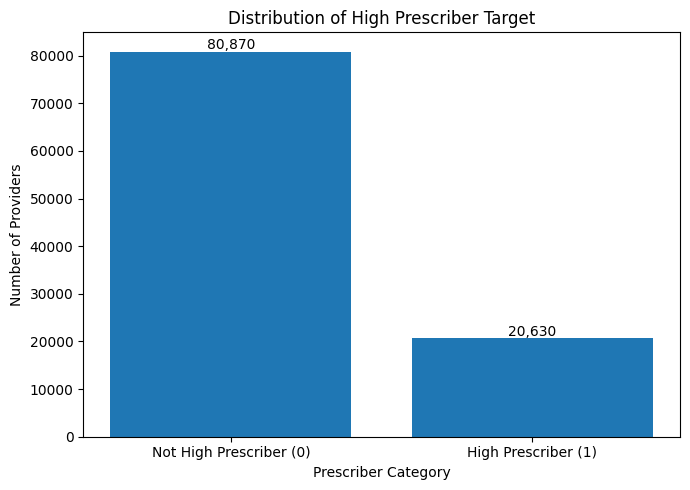

In [84]:
import matplotlib.pyplot as plt
target_counts = y.value_counts().sort_index()

plt.figure(figsize = (7, 5))
plt.bar(
    ["Not High Prescriber (0)", "High Prescriber (1)"],
    target_counts.values
)
plt.title("Distribution of High Prescriber Target")
plt.xlabel("Prescriber Category")
plt.ylabel("Number of Providers")

for i, value in enumerate(target_counts.values):
  plt.text(i, value + 500, f"{value:,}", ha = "center")

plt.tight_layout()
plt.show()

In [32]:
from google.colab import files
files.download("hcp_targeting_model_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Feature Engineering & Model Preparation**

In [33]:
print("Faeture columns:")
print(x.columns.tolist())
print("\nFeature matrix shape:")
print(x.shape)
print("\nData types:")
print(x.dtypes)
print("\nStatistical summary:")
display(x.describe().T)

Faeture columns:
['Farxiga_Tot_30day_Fills', 'Invokana_Tot_30day_Fills', 'Jardiance_Tot_30day_Fills', 'Steglatro_Tot_30day_Fills', 'Farxiga_Tot_Clms', 'Invokana_Tot_Clms', 'Jardiance_Tot_Clms', 'Steglatro_Tot_Clms', 'Farxiga_Tot_Day_Suply', 'Invokana_Tot_Day_Suply', 'Jardiance_Tot_Day_Suply', 'Steglatro_Tot_Day_Suply', 'Farxiga_Tot_Drug_Cst', 'Invokana_Tot_Drug_Cst', 'Jardiance_Tot_Drug_Cst', 'Steglatro_Tot_Drug_Cst']

Feature matrix shape:
(101500, 16)

Data types:
Farxiga_Tot_30day_Fills      float64
Invokana_Tot_30day_Fills     float64
Jardiance_Tot_30day_Fills    float64
Steglatro_Tot_30day_Fills    float64
Farxiga_Tot_Clms               int64
Invokana_Tot_Clms              int64
Jardiance_Tot_Clms             int64
Steglatro_Tot_Clms             int64
Farxiga_Tot_Day_Suply          int64
Invokana_Tot_Day_Suply         int64
Jardiance_Tot_Day_Suply        int64
Steglatro_Tot_Day_Suply        int64
Farxiga_Tot_Drug_Cst         float64
Invokana_Tot_Drug_Cst        float64
Jardiance_T

,count,mean,std,min,25%,50%,75%,max
Farxiga_Tot_30day_Fills,101500.0,19.484053,43.668829,0.0,0.0000,0.0,27.0000,1595.00
Invokana_Tot_30day_Fills,101500.0,4.402830,16.738146,0.0,0.0000,0.0,0.0000,756.00
Jardiance_Tot_30day_Fills,101500.0,57.583653,75.804807,0.0,20.0000,37.0,69.0000,2444.50
Steglatro_Tot_30day_Fills,101500.0,0.140403,2.245467,0.0,0.0000,0.0,0.0000,215.00
Farxiga_Tot_Clms,101500.0,11.858059,27.292603,0.0,0.0000,0.0,16.0000,1065.00
Invokana_Tot_Clms,101500.0,2.698887,9.759224,0.0,0.0000,0.0,0.0000,453.00
Jardiance_Tot_Clms,101500.0,32.671764,43.731186,0.0,13.0000,21.0,38.0000,1734.00
Steglatro_Tot_Clms,101500.0,0.105842,1.597062,0.0,0.0000,0.0,0.0000,114.00
Farxiga_Tot_Day_Suply,101500.0,575.076404,1297.244033,0.0,0.0000,0.0,810.0000,47850.00
Invokana_Tot_Day_Suply,101500.0,129.300345,496.755525,0.0,0.0000,0.0,0.0000,22680.00


In [34]:
zero_counts = (x == 0).sum().sort_values(ascending = False)
zero_percentage = ((x == 0).mean() * 100).sort_values(ascending = False)
zero_analysis = pd.DataFrame({
    "Zero_Count" : zero_counts,
    "Zero_Percentage" : zero_percentage.round(2)
})

display(zero_analysis)

,Zero_Count,Zero_Percentage
Steglatro_Tot_30day_Fills,100866,99.38
Steglatro_Tot_Clms,100866,99.38
Steglatro_Tot_Drug_Cst,100866,99.38
Steglatro_Tot_Day_Suply,100866,99.38
Invokana_Tot_Day_Suply,88620,87.31
Invokana_Tot_Drug_Cst,88620,87.31
Invokana_Tot_Clms,88620,87.31
Invokana_Tot_30day_Fills,88620,87.31
Farxiga_Tot_Drug_Cst,62579,61.65
Farxiga_Tot_Day_Suply,62579,61.65


In [35]:
x_engineered = x.copy()
print("Original features:", x.shape[1])
print("\nEngineered dataset shape:", x_engineered.shape)

Original features: 16

Engineered dataset shape: (101500, 16)


In [36]:
x_engineered["total_sglt2_claims_2021"] = (
    x_engineered["Jardiance_Tot_Clms"] + x_engineered["Farxiga_Tot_Clms"] + x_engineered["Invokana_Tot_Clms"] + x_engineered["Steglatro_Tot_Clms"]
)
print("New feature created!")
display(x_engineered[["total_sglt2_claims_2021"]].describe())

New feature created!


,total_sglt2_claims_2021
count,101500.000000
mean,47.334552
std,65.953675
min,11.000000
25%,16.000000
50%,27.000000
75%,53.000000
max,3145.000000


In [37]:
x_engineered["competitor_claims_2021"] = (
    x_engineered["Farxiga_Tot_Clms"] + x_engineered["Invokana_Tot_Clms"] + x_engineered["Steglatro_Tot_Clms"]
)
print("Competitor claims feature created!")
display(x_engineered[["competitor_claims_2021"]].describe())

Competitor claims feature created!


,competitor_claims_2021
count,101500.000000
mean,14.662788
std,31.989898
min,0.000000
25%,0.000000
50%,0.000000
75%,18.000000
max,1434.000000


In [38]:
x_engineered["jardiance_claim_share_2021"] = (
    x_engineered["Jardiance_Tot_Clms"] / x_engineered["total_sglt2_claims_2021"]
)
print("Jardiance claim share feature created!")
display(x_engineered[["jardiance_claim_share_2021"]].describe())

Jardiance claim share feature created!


,jardiance_claim_share_2021
count,101500.000000
mean,0.730413
std,0.362924
min,0.000000
25%,0.518519
50%,1.000000
75%,1.000000
max,1.000000


In [39]:
competitor_cols = ["Farxiga_Tot_Clms", "Invokana_Tot_Clms", "Steglatro_Tot_Clms"]
x_engineered["num_competitor_drugs_2021"] = (x_engineered[competitor_cols] > 0).sum(axis = 1)
print("Competitor drug count feature created!")
display(x_engineered[["num_competitor_drugs_2021"]].value_counts().sort_index())

Competitor drug count feature created!


,count
num_competitor_drugs_2021,
0,56095
1,38555
2,6670
3,180


In [40]:
cost_cols = ["Jardiance_Tot_Drug_Cst", "Farxiga_Tot_Drug_Cst", "Invokana_Tot_Drug_Cst", "Steglatro_Tot_Drug_Cst"]
x_engineered["total_sglt2_drug_cost_2021"] = (x_engineered[cost_cols].sum(axis = 1))

print("TOtal SGLT2 drug cost feature created!")
display(x_engineered[["total_sglt2_drug_cost_2021"]].describe())

TOtal SGLT2 drug cost feature created!


,total_sglt2_drug_cost_2021
count,1.015000e+05
mean,4.423741e+04
std,6.138939e+04
min,1.688000e+01
25%,1.439111e+04
50%,2.555888e+04
75%,5.038200e+04
max,2.279167e+06


In [41]:
new_features = [
    "total_sglt2_claims_2021",
    "competitor_claims_2021",
    "jardiance_claim_share_2021",
    "num_competitor_drugs_2021",
    "total_sglt2_drug_cost_2021"
]

print("Engineered feature summary:")
display(x_engineered[new_features].describe().T)

print("\nMissing values:")
print(x_engineered[new_features].isnull().sum())

Engineered feature summary:


,count,mean,std,min,25%,50%,75%,max
total_sglt2_claims_2021,101500.0,47.334552,65.953675,11.00,16.000000,27.000,53.0000,3145.00
competitor_claims_2021,101500.0,14.662788,31.989898,0.00,0.000000,0.000,18.0000,1434.00
jardiance_claim_share_2021,101500.0,0.730413,0.362924,0.00,0.518519,1.000,1.0000,1.00
num_competitor_drugs_2021,101500.0,0.516601,0.625937,0.00,0.000000,0.000,1.0000,3.00
total_sglt2_drug_cost_2021,101500.0,44237.409592,61389.392828,16.88,14391.112500,25558.875,50382.0025,2279167.47



Missing values:
total_sglt2_claims_2021       0
competitor_claims_2021        0
jardiance_claim_share_2021    0
num_competitor_drugs_2021     0
total_sglt2_drug_cost_2021    0
dtype: int64


In [42]:
skew_analysis = x_engineered[new_features].skew().sort_values(ascending = False)
print("Skewness of engineered features:")
display(skew_analysis.to_frame(name = "Skewness"))

Skewness of engineered features:


,Skewness
competitor_claims_2021,8.540975
total_sglt2_claims_2021,8.042102
total_sglt2_drug_cost_2021,6.661731
num_competitor_drugs_2021,0.849710
jardiance_claim_share_2021,-1.043347


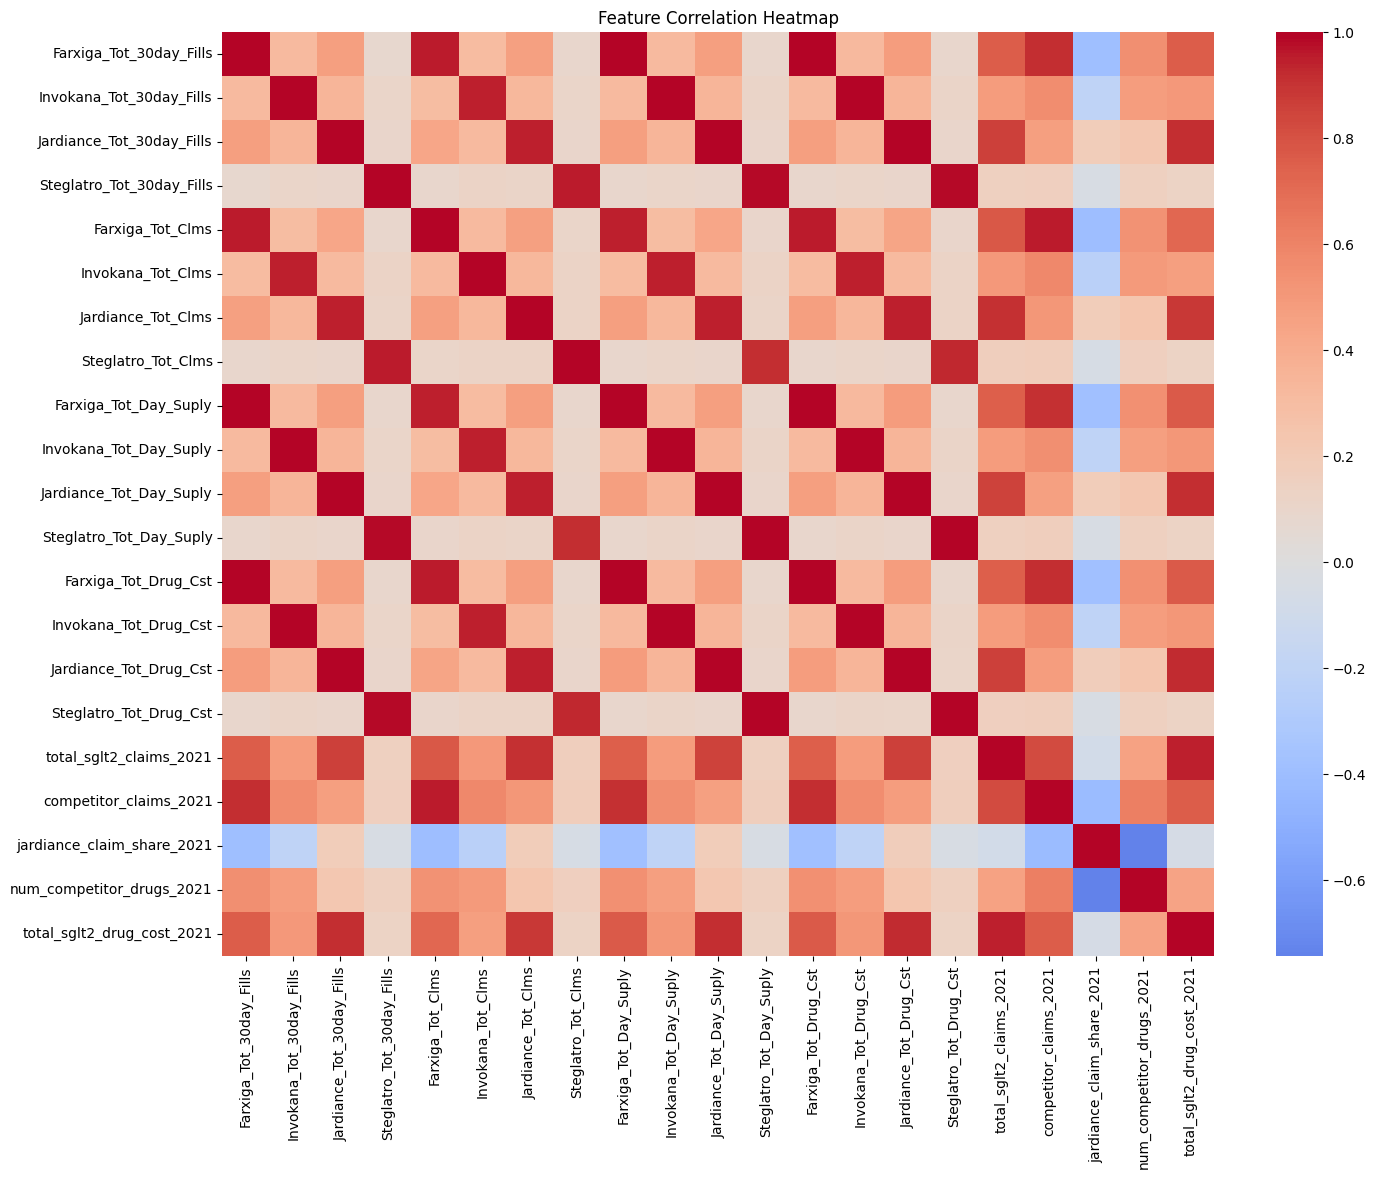

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
correlation_matrix = x_engineered.corr()
plt.figure(figsize = (16, 12))
sns.heatmap(
    correlation_matrix,
    cmap = "coolwarm",
    center = 0,
    annot = False
)
plt.title("Feature Correlation Heatmap")
plt.show()

In [44]:
log_cols = [col for col in x_engineered.columns if col.endswith("_log")]
x_engineered = x_engineered.drop(columns = log_cols)
print("Final feature matrix shape:", x_engineered.shape)
print("\nMissing values:", x_engineered.isnull().sum().sum())
print("\nFeature names:")
print(x_engineered.columns.tolist())

Final feature matrix shape: (101500, 21)

Missing values: 0

Feature names:
['Farxiga_Tot_30day_Fills', 'Invokana_Tot_30day_Fills', 'Jardiance_Tot_30day_Fills', 'Steglatro_Tot_30day_Fills', 'Farxiga_Tot_Clms', 'Invokana_Tot_Clms', 'Jardiance_Tot_Clms', 'Steglatro_Tot_Clms', 'Farxiga_Tot_Day_Suply', 'Invokana_Tot_Day_Suply', 'Jardiance_Tot_Day_Suply', 'Steglatro_Tot_Day_Suply', 'Farxiga_Tot_Drug_Cst', 'Invokana_Tot_Drug_Cst', 'Jardiance_Tot_Drug_Cst', 'Steglatro_Tot_Drug_Cst', 'total_sglt2_claims_2021', 'competitor_claims_2021', 'jardiance_claim_share_2021', 'num_competitor_drugs_2021', 'total_sglt2_drug_cost_2021']


In [45]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x_engineered,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

print("Training features:", x_train.shape)
print("\nTesting features:", x_test.shape)

print("\nTrainig target distribution:")
print(y_train.value_counts(normalize = True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize = True) * 100)

Training features: (81200, 21)

Testing features: (20300, 21)

Trainig target distribution:
high_prescriber_2022
0    79.674877
1    20.325123
Name: proportion, dtype: float64

Testing target distribution:
high_prescriber_2022
0    79.674877
1    20.325123
Name: proportion, dtype: float64


In [46]:
print("Final prepration check")

print("\nx_train missing values:", x_train.isnull().sum().sum())
print("\nx_test missing values:", x_test.isnull().sum().sum())

print("\ny_train missing values:", y_train.isnull().sum())
print("\ny_test missing values:", y_test.isnull().sum())

print("\nTotal training records:", len(x_train))
print("\nTotal testing records:", len(x_test))

Final prepration check

x_train missing values: 0

x_test missing values: 0

y_train missing values: 0

y_test missing values: 0

Total training records: 81200

Total testing records: 20300


# **ML Models**

In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


In [48]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter = 1000))
])
print("Logistic regression model created!")

Logistic regression model created!


In [49]:
logistic_model.fit(x_train, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [50]:
y_pred_logistics = logistic_model.predict(x_test)
y_prob_logistics = logistic_model.predict_proba(x_test)[:,1]
print("Preductions generated.")

Preductions generated.


In [51]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
logistic_results = {
    "Accuracy" : accuracy_score(y_test, y_pred_logistics),
    "Precision" : precision_score(y_test,y_pred_logistics, zero_division = 0),
    "Recall" : recall_score(y_test, y_pred_logistics, zero_division = 0),
    "F1 Score" : f1_score(y_test, y_pred_logistics, zero_division = 0),
    "ROC-AUC" : roc_auc_score(y_test, y_prob_logistics),
    "PR-AUC" : average_precision_score(y_test, y_prob_logistics)
}

In [52]:
print(logistic_results)

{'Accuracy': 0.8999507389162562, 'Precision': 0.8467394902350215, 'Recall': 0.6199709161415414, 'F1 Score': 0.7158248216034699, 'ROC-AUC': np.float64(0.9201119283799346), 'PR-AUC': np.float64(0.8197488473437416)}


Confusion matrix:
[[15711   463]
 [ 1568  2558]]


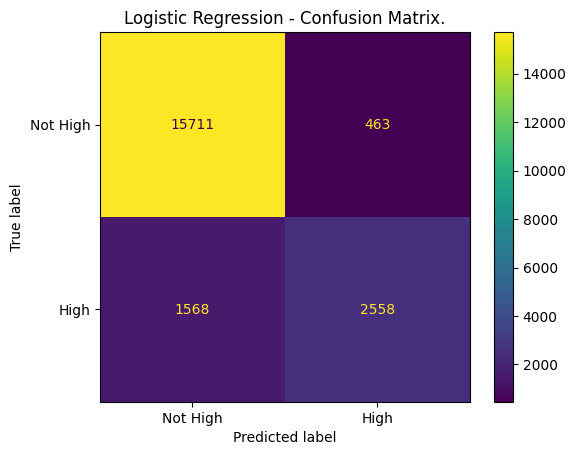

In [53]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred_logistics)

print("Confusion matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels = ["Not High", "High"]
).plot()
plt.title("Logistic Regression - Confusion Matrix.")
plt.show()

In [54]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators = 200,
    max_depth = None,
    min_samples_split = 2,
    min_samples_leaf = 1,
    class_weight = "balanced",
    random_state = 42,
    n_jobs = -1
)

print("Random Forest model is ready!")

Random Forest model is ready!


In [55]:
rf_model.fit(x_train,y_train)
print("Random Forest training completed!")

Random Forest training completed!


In [56]:
y_pred_rf = rf_model.predict(x_test)
y_prob_rf = rf_model.predict_proba(x_test)[:,1]

print("Random Forest prediction generated.")

Random Forest prediction generated.


In [57]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
rf_results = {
    "Accuracy" : accuracy_score(y_test, y_pred_rf),
    "Precision" : precision_score(y_test, y_pred_rf, zero_division = 0),
    "Recall" : recall_score(y_test, y_pred_rf, zero_division = 0),
    "F1 Score" : f1_score(y_test, y_pred_rf, zero_division = 0),
    "ROC-AUC" : roc_auc_score(y_test, y_prob_rf),
    "PR-AUC" : average_precision_score(y_test, y_prob_rf)
}

In [58]:
print(rf_results)

{'Accuracy': 0.8882266009852217, 'Precision': 0.7665805340223945, 'Recall': 0.6471158507028599, 'F1 Score': 0.7018004994085951, 'ROC-AUC': np.float64(0.9009649050458955), 'PR-AUC': np.float64(0.7813902400756041)}


In [59]:
from sklearn.ensemble import GradientBoostingClassifier
gb_model = GradientBoostingClassifier(
    n_estimators = 100,
    learning_rate = 0.1,
    max_depth = 3,
    random_state = 42
)

print("Gradient Boosting model is created!")

Gradient Boosting model is created!


In [60]:
gb_model.fit(x_train, y_train)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [61]:
y_pred_gb = gb_model.predict(x_test)
y_prob_gb = gb_model.predict_proba(x_test)[:,1]

print("Gradient Boosting predictions generated.")

Gradient Boosting predictions generated.


In [62]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
gb_results = {
    "Accuracy" : accuracy_score(y_test, y_pred_gb),
    "Precision" : precision_score(y_test, y_pred_gb, zero_division = 0),
    "Recall" : recall_score(y_test, y_pred_gb, zero_division = 0),
    "F1 Score" : f1_score(y_test, y_pred_gb, zero_division = 0),
    "ROC-AUC" : roc_auc_score(y_test, y_prob_gb),
    "PR-AUC" : average_precision_score(y_test, y_prob_gb)
}

In [63]:
print(gb_results)

{'Accuracy': 0.9004926108374385, 'Precision': 0.8202554744525548, 'Recall': 0.6536597188560349, 'F1 Score': 0.7275424871864041, 'ROC-AUC': np.float64(0.9212850049099464), 'PR-AUC': np.float64(0.8185340456850854)}


In [64]:
import pandas as pd
comparison_df = pd.DataFrame(
    [logistic_results, rf_results, gb_results],
    index = ["Logistic Regression", "Random Forest", "Gradient Boosting"]
)
comparison_df = comparison_df.T

print(comparison_df.round(4))

           Logistic Regression  Random Forest  Gradient Boosting
Accuracy                0.9000         0.8882             0.9005
Precision               0.8467         0.7666             0.8203
Recall                  0.6200         0.6471             0.6537
F1 Score                0.7158         0.7018             0.7275
ROC-AUC                 0.9201         0.9010             0.9213
PR-AUC                  0.8197         0.7814             0.8185


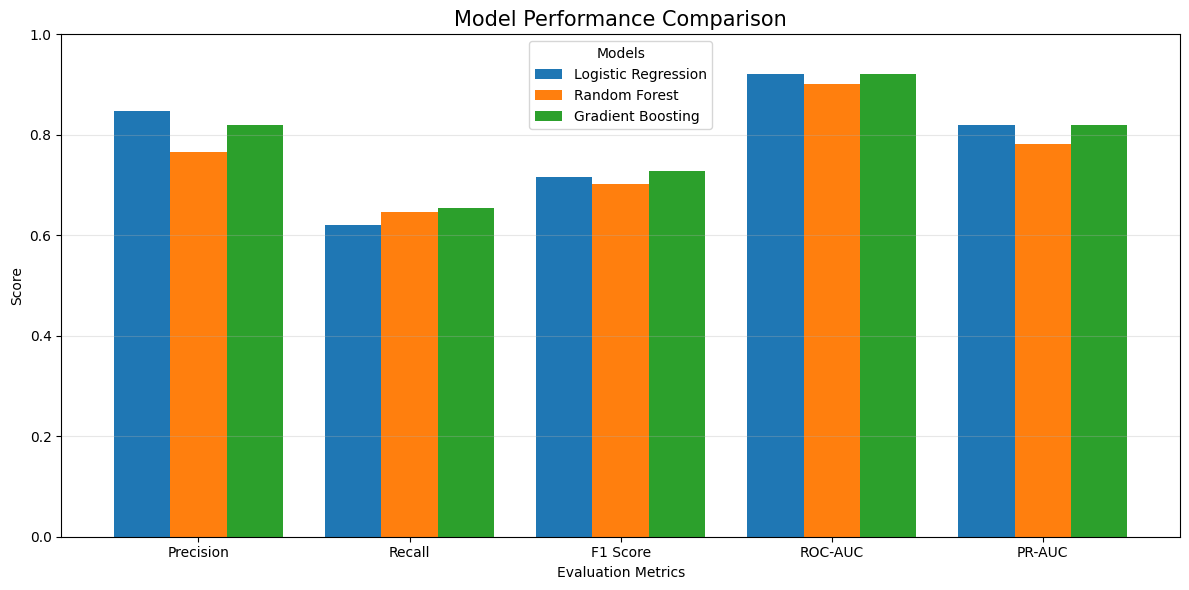

In [65]:
import matplotlib.pyplot as plt
metrics = [
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "PR-AUC"
]

comparison_plot = comparison_df.loc[metrics]
comparison_plot.plot(
    kind = "bar",
    figsize = (12, 6),
    width = 0.8
)

plt.title("Model Performance Comparison", fontsize = 15)
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation = 0)
plt.legend(title = "Models")
plt.grid(axis = "y", alpha = 0.3)
plt.tight_layout()
plt.show()

In [66]:
comparison_df.to_csv("model_comparison.csv")

from google.colab import files
files.download("model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Model Finalization & HCP Prediction**

In [67]:
final_model = gb_model
print("Final model selected: Gradient Boosting")

Final model selected: Gradient Boosting


In [68]:
import pandas as pd
feature_importance_df = pd.DataFrame({
    "Feature" : x_train.columns,
    "Importance" :final_model.feature_importances_
})
feature_importance_df = feature_importance_df.sort_values(
    by = "Importance",
    ascending = False
)

print(feature_importance_df)

                       Feature  Importance
6           Jardiance_Tot_Clms    0.942050
2    Jardiance_Tot_30day_Fills    0.023705
16     total_sglt2_claims_2021    0.018727
10     Jardiance_Tot_Day_Suply    0.006639
20  total_sglt2_drug_cost_2021    0.003510
14      Jardiance_Tot_Drug_Cst    0.002017
8        Farxiga_Tot_Day_Suply    0.000553
12        Farxiga_Tot_Drug_Cst    0.000477
13       Invokana_Tot_Drug_Cst    0.000403
18  jardiance_claim_share_2021    0.000394
4             Farxiga_Tot_Clms    0.000339
17      competitor_claims_2021    0.000281
0      Farxiga_Tot_30day_Fills    0.000271
5            Invokana_Tot_Clms    0.000178
9       Invokana_Tot_Day_Suply    0.000162
7           Steglatro_Tot_Clms    0.000091
11     Steglatro_Tot_Day_Suply    0.000082
19   num_competitor_drugs_2021    0.000072
3    Steglatro_Tot_30day_Fills    0.000024
1     Invokana_Tot_30day_Fills    0.000014
15      Steglatro_Tot_Drug_Cst    0.000012


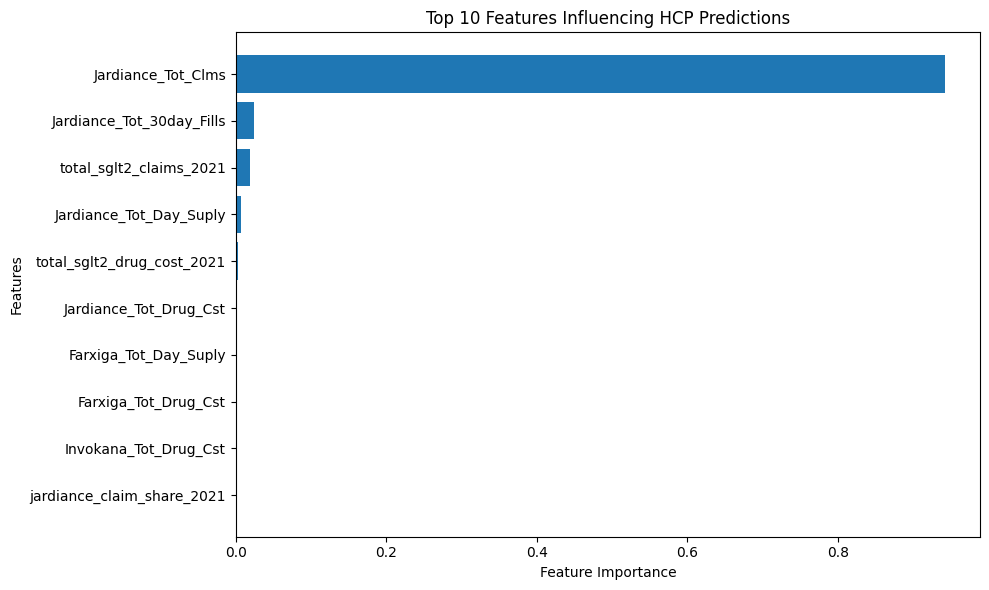

In [69]:
import matplotlib.pyplot as plt
top_features = feature_importance_df.head(10)
plt.figure(figsize= (10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Features Influencing HCP Predictions")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [70]:
feature_importance_df.to_csv(
    "feature_importance.csv",
    index = False
)

In [71]:
from google.colab import files
files.download("feature_importance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [72]:
sample_hcps = x_test.head()
sample_predictions = final_model.predict(sample_hcps)
sample_probabilities = final_model.predict_proba(sample_hcps)[:,1]

print("Predictions:", sample_predictions)
print("High prescriber probabilities:", sample_probabilities)

Predictions: [0 0 0 0 0]
High prescriber probabilities: [0.0872126  0.01671488 0.21992835 0.01304788 0.18472037]


In [73]:
sample_hcps = x_test.head(10)
sample_predictions = final_model.predict(sample_hcps)
sample_probabilities = final_model.predict_proba(sample_hcps)[:,1]

hcp_prediction_df = pd.DataFrame({
    "NPI" : modeling_df.loc[sample_hcps.index,"Prscrbr_NPI"].values,
    "Predicted_Class" : sample_predictions,
    "High_Prescriber_Probability" : sample_probabilities
})

hcp_prediction_df["Probability_Percentage"] = (hcp_prediction_df["High_Prescriber_Probability"] * 100).round(2)

print(hcp_prediction_df)

          NPI  Predicted_Class  High_Prescriber_Probability  \
0  1104972751                0                     0.087213   
1  1467701847                0                     0.016715   
2  1366685828                0                     0.219928   
3  1023288990                0                     0.013048   
4  1124273313                0                     0.184720   
5  1255714069                1                     0.951579   
6  1366596405                0                     0.047036   
7  1902433550                0                     0.018234   
8  1215926795                0                     0.036702   
9  1225030513                0                     0.015051   

   Probability_Percentage  
0                    8.72  
1                    1.67  
2                   21.99  
3                    1.30  
4                   18.47  
5                   95.16  
6                    4.70  
7                    1.82  
8                    3.67  
9                    1.51 

In [74]:
hcp_prediction_df.to_csv("sample_hcp_predictions.csv", index = False)

In [75]:
from google.colab import files
files.download("sample_hcp_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [76]:
ranked_hcps = hcp_prediction_df.sort_values(
    by = "High_Prescriber_Probability",
    ascending = False
).reset_index(drop = True)
ranked_hcps.insert(
    0,
    "Rank",
    range(1, len(ranked_hcps) + 1)
)

print(ranked_hcps)

   Rank         NPI  Predicted_Class  High_Prescriber_Probability  \
0     1  1255714069                1                     0.951579   
1     2  1366685828                0                     0.219928   
2     3  1124273313                0                     0.184720   
3     4  1104972751                0                     0.087213   
4     5  1366596405                0                     0.047036   
5     6  1215926795                0                     0.036702   
6     7  1902433550                0                     0.018234   
7     8  1467701847                0                     0.016715   
8     9  1225030513                0                     0.015051   
9    10  1023288990                0                     0.013048   

   Probability_Percentage  
0                   95.16  
1                   21.99  
2                   18.47  
3                    8.72  
4                    4.70  
5                    3.67  
6                    1.82  
7               

In [77]:
ranked_hcps.to_csv("ranked_hcp_predictions.csv", index = False)

In [78]:
from google.colab import files
files.download("ranked_hcp_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [79]:
import joblib
joblib.dump(final_model, "hcp_gradient_boosting_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [80]:
from google.colab import files
files.download("hcp_gradient_boosting_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [81]:
loaded_model = joblib.load("hcp_gradient_boosting_model.pkl")
test_predictions = loaded_model.predict(x_test.head())

print("Loaded model predictions:", test_predictions)

Loaded model predictions: [0 0 0 0 0]


In [82]:
import os
required_files = [
    "model_comparison.csv",
    "feature_importance.csv",
    "sample_hcp_predictions.csv",
    "ranked_hcp_predictions.csv",
    "hcp_gradient_boosting_model.pkl"
]
for file in required_files:
  if os.path.exists(file):
    print(f"{file} - Available")
  else:
    print(f"{file} - Missing")

model_comparison.csv - Available
feature_importance.csv - Available
sample_hcp_predictions.csv - Available
ranked_hcp_predictions.csv - Available
hcp_gradient_boosting_model.pkl - Available


In [83]:
print("FINAL PROJECT CHECK")
print("********************")

print("Original features:", x.shape)
print("Engineered features:", x_engineered.shape)
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nFinal model:", type(final_model).__name__)
print("\nModel test predictions:")
print(loaded_model.predict(x_test.head()))

FINAL PROJECT CHECK
********************
Original features: (101500, 16)
Engineered features: (101500, 21)
Training data: (81200, 21)
Testing data: (20300, 21)

Target distribution:
high_prescriber_2022
0    80870
1    20630
Name: count, dtype: int64

Final model: GradientBoostingClassifier

Model test predictions:
[0 0 0 0 0]


# Final Project Summary

## Project: HCP Targeting & Prescription Prediction

### 1. Project Overview
This project develops a machine learning-based approach to identify healthcare providers (HCPs) who are likely to become high Jardiance prescribers. It uses historical Medicare Part D prescription data published by CMS.

### 2. Dataset
- Data source: CMS Medicare Part D Prescribers.
- Years used: 2021 and 2022.
- Drugs analysed: Jardiance, Farxiga, Invokana and Steglatro.
- Total providers in the modelling cohort: 101,500.
- Original features: 16.
- Engineered features: 5.
- Final features: 21.

### 3. Methodology
1. Collected prescription data through the CMS Data API.
2. Cleaned and aggregated drug-level records at provider level.
3. Constructed the 2022 high-prescriber target using the 80th percentile of Jardiance claims.
4. Created additional features to capture prescribing patterns.
5. Split the data into training and testing sets.
6. Trained and evaluated three classification algorithms.
7. Selected Gradient Boosting based on overall evaluation performance.
8. Generated HCP-level predictions and ranked providers by predicted probability.

### 4. Model Performance

| Metric | Gradient Boosting |
|---|---:|
| Accuracy | 90.05% |
| Precision | 82.03% |
| Recall | 65.37% |
| F1 Score | 72.75% |
| ROC-AUC | 92.13% |
| PR-AUC | 81.85% |

### 5. Final Deliverables
- Processed provider-level datasets.
- Engineered modelling dataset.
- Model comparison results.
- Feature importance analysis.
- HCP prediction and ranking outputs.
- Saved Gradient Boosting model.

### 6. Conclusion
The project demonstrates how historical prescription patterns and machine learning can support data-driven HCP targeting. The resulting predictions can help prioritize providers for further analysis and potential engagement.

### 7. Limitations
- The analysis is based on Medicare Part D data and does not represent every prescription or healthcare provider in the US.
- The high-prescriber threshold is defined using the 80th percentile of the selected modelling cohort.
- Model probabilities are estimates, not guaranteed future prescribing outcomes.
- Further validation on additional years and independent provider cohorts would strengthen the model.